*Importing Necessary Libraries*

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score

warnings.filterwarnings('ignore') # for ignoring warnings to keep the notebook clean (relevant issues are handled in later sections)

*Loading Dataset*

In [2]:
# read in csv file as a DataFrame
df= pd.read_csv('train.csv')
df



,Location,Cross_Street,Latitude,Longitude,Date_Reported,Date_Occurred,Time_Occurred,Area_ID,Area_Name,Reporting_District_no,...,Victim_Age,Victim_Sex,Victim_Descent,Premise_Code,Premise_Description,Weapon_Used_Code,Weapon_Description,Status,Status_Description,Crime_Category
0,4500 CARPENTER AV,NaN,34.1522,-118.3910,03/09/2020 12:00:00 AM,03/06/2020 12:00:00 AM,1800.0,15.0,N Hollywood,1563.0,...,75.0,M,W,101.0,STREET,NaN,NaN,IC,Invest Cont,Property Crimes
1,45TH ST,ALAMEDA ST,34.0028,-118.2391,02/27/2020 12:00:00 AM,02/27/2020 12:00:00 AM,1345.0,13.0,Newton,1367.0,...,41.0,M,H,216.0,SWAP MEET,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Property Crimes
2,600 E MARTIN LUTHER KING JR BL,NaN,34.0111,-118.2653,08/21/2020 12:00:00 AM,08/21/2020 12:00:00 AM,605.0,13.0,Newton,1343.0,...,67.0,M,B,501.0,SINGLE FAMILY DWELLING,NaN,NaN,IC,Invest Cont,Property Crimes
3,14900 ORO GRANDE ST,NaN,34.2953,-118.4590,11/08/2020 12:00:00 AM,11/06/2020 12:00:00 AM,1800.0,19.0,Mission,1924.0,...,61.0,M,H,101.0,STREET,NaN,NaN,IC,Invest Cont,Property Crimes
4,7100 S VERMONT AV,NaN,33.9787,-118.2918,02/25/2020 12:00:00 AM,02/25/2020 12:00:00 AM,1130.0,12.0,77th Street,1245.0,...,0.0,X,X,401.0,MINI-MART,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Property Crimes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,5100 W ADAMS BL,NaN,34.0334,-118.3523,05/24/2020 12:00:00 AM,05/24/2020 12:00:00 AM,700.0,3.0,Southwest,303.0,...,51.0,M,H,501.0,SINGLE FAMILY DWELLING,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Violent Crimes
19996,16900 ROSCOE BL,NaN,34.2212,-118.5011,12/25/2020 12:00:00 AM,12/25/2020 12:00:00 AM,259.0,10.0,West Valley,1008.0,...,0.0,M,W,301.0,GAS STATION,NaN,NaN,IC,Invest Cont,Property Crimes
19997,1000 S SHENANDOAH ST,NaN,34.0571,-118.3815,09/25/2020 12:00:00 AM,09/25/2020 12:00:00 AM,1400.0,8.0,West LA,849.0,...,42.0,M,H,102.0,SIDEWALK,NaN,NaN,IC,Invest Cont,Property Crimes
19998,300 W SEPULVEDA ST,NaN,33.7451,-118.2835,06/10/2020 12:00:00 AM,06/10/2020 12:00:00 AM,600.0,5.0,Harbor,558.0,...,76.0,F,H,501.0,SINGLE FAMILY DWELLING,NaN,NaN,IC,Invest Cont,Crimes against Public Order


*Data Preprocessing*

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Location               20000 non-null  object 
 1   Cross_Street           3448 non-null   object 
 2   Latitude               20000 non-null  float64
 3   Longitude              20000 non-null  float64
 4   Date_Reported          20000 non-null  object 
 5   Date_Occurred          20000 non-null  object 
 6   Time_Occurred          20000 non-null  float64
 7   Area_ID                20000 non-null  float64
 8   Area_Name              20000 non-null  object 
 9   Reporting_District_no  20000 non-null  float64
 10  Part 1-2               20000 non-null  float64
 11  Modus_Operandi         17259 non-null  object 
 12  Victim_Age             20000 non-null  float64
 13  Victim_Sex             17376 non-null  object 
 14  Victim_Descent         17376 non-null  object 
 15  Pr

In [4]:
df.describe()

,Latitude,Longitude,Time_Occurred,Area_ID,Reporting_District_no,Part 1-2,Victim_Age,Premise_Code,Weapon_Used_Code
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,7335.000000
mean,33.940704,-117.893072,1352.380350,10.834250,1129.599200,1.418150,30.135000,297.176950,366.405044
std,2.126810,7.377726,646.100291,6.033166,603.330519,0.493267,21.863645,212.007298,120.485687
min,0.000000,-118.663400,1.000000,1.000000,101.000000,1.000000,-2.000000,101.000000,101.000000
25%,34.009200,-118.429700,930.000000,6.000000,632.000000,1.000000,12.000000,101.000000,312.000000
50%,34.058700,-118.323000,1430.000000,11.000000,1162.000000,1.000000,31.000000,203.000000,400.000000
75%,34.165025,-118.274400,1900.000000,16.000000,1622.000000,2.000000,46.000000,501.000000,400.000000
max,34.328100,0.000000,2359.000000,21.000000,2197.000000,2.000000,99.000000,969.000000,515.000000


In [5]:
df.shape

(20000, 22)

*Checking Duplicate Values*

In [6]:
df.duplicated().sum()

13

*Removing Duplicates Values*

In [7]:
# Remove Duplicates
df = df.drop_duplicates()

In [8]:
df.duplicated().sum()

0

In [9]:
df.columns

Index(['Location', 'Cross_Street', 'Latitude', 'Longitude', 'Date_Reported',
       'Date_Occurred', 'Time_Occurred', 'Area_ID', 'Area_Name',
       'Reporting_District_no', 'Part 1-2', 'Modus_Operandi', 'Victim_Age',
       'Victim_Sex', 'Victim_Descent', 'Premise_Code', 'Premise_Description',
       'Weapon_Used_Code', 'Weapon_Description', 'Status',
       'Status_Description', 'Crime_Category'],
      dtype='object')

In [10]:
df.nunique()

Location                 12399
Cross_Street              1495
Latitude                  3622
Longitude                 3578
Date_Reported              811
Date_Occurred              366
Time_Occurred              996
Area_ID                     21
Area_Name                   21
Reporting_District_no     1120
Part 1-2                     2
Modus_Operandi           10489
Victim_Age                 100
Victim_Sex                   4
Victim_Descent              17
Premise_Code               217
Premise_Description        216
Weapon_Used_Code            57
Weapon_Description          57
Status                       5
Status_Description           5
Crime_Category               6
dtype: int64

*Checking For Null Values*

In [11]:
df.isnull().sum()

Location                     0
Cross_Street             16540
Latitude                     0
Longitude                    0
Date_Reported                0
Date_Occurred                0
Time_Occurred                0
Area_ID                      0
Area_Name                    0
Reporting_District_no        0
Part 1-2                     0
Modus_Operandi            2738
Victim_Age                   0
Victim_Sex                2622
Victim_Descent            2622
Premise_Code                 0
Premise_Description          5
Weapon_Used_Code         12657
Weapon_Description       12657
Status                       0
Status_Description           0
Crime_Category               0
dtype: int64

*Treating Missing Values*

In [12]:
df['Victim_Descent'] = df['Victim_Descent'].fillna(df['Victim_Descent'].mode()[0])
print(df['Victim_Descent'])

0        W
1        H
2        B
3        H
4        X
        ..
19995    H
19996    W
19997    H
19998    H
19999    H
Name: Victim_Descent, Length: 19987, dtype: object


In [13]:
df['Cross_Street'] = df['Cross_Street'].fillna(df['Cross_Street'].mode()[0])
print(df['Cross_Street'])

0                               BROADWAY
1        ALAMEDA                      ST
2                               BROADWAY
3                               BROADWAY
4                               BROADWAY
                      ...               
19995                           BROADWAY
19996                           BROADWAY
19997                           BROADWAY
19998                           BROADWAY
19999    VERNON                       AV
Name: Cross_Street, Length: 19987, dtype: object


In [14]:
df['Modus_Operandi'] = df['Modus_Operandi'].fillna(df['Modus_Operandi'].mode()[0])
print(df['Modus_Operandi'])

0                                           0385
1        0906 0352 0371 0446 1822 0344 0416 0417
2                                      0329 1202
3                                      0329 1300
4                  0416 0945 1822 0400 0417 0344
                          ...                   
19995                        0416 0446 2004 0913
19996                   1822 0209 0344 1414 1420
19997                             0344 1822 1420
19998              1202 2038 0913 0602 1242 0553
19999                                       0344
Name: Modus_Operandi, Length: 19987, dtype: object


In [15]:
df['Weapon_Description'] = df['Weapon_Description'].fillna(df['Weapon_Description'].mode()[0])
print(df['Weapon_Description'])

0        STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
1        STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
2        STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
3        STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
4        STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
                              ...                      
19995    STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
19996    STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
19997    STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
19998    STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
19999    STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)
Name: Weapon_Description, Length: 19987, dtype: object


In [16]:
df['Victim_Sex'] = df['Victim_Sex'].fillna(df['Victim_Sex'].mode()[0])
print(df['Victim_Sex'])


0        M
1        M
2        M
3        M
4        X
        ..
19995    M
19996    M
19997    M
19998    F
19999    M
Name: Victim_Sex, Length: 19987, dtype: object


In [17]:
df['Premise_Description'] = df['Premise_Description'].fillna(df['Premise_Description'].mode()[0])
print(df['Premise_Description'])


0                        STREET
1                     SWAP MEET
2        SINGLE FAMILY DWELLING
3                        STREET
4                     MINI-MART
                  ...          
19995    SINGLE FAMILY DWELLING
19996               GAS STATION
19997                  SIDEWALK
19998    SINGLE FAMILY DWELLING
19999                    STREET
Name: Premise_Description, Length: 19987, dtype: object


In [18]:
# Fill NaN in 'Area_Name' with the most frequent value (mode)
df['Area_Name'] = df['Area_Name'].fillna(df['Area_Name'].mode()[0])

In [19]:
# Impute missing values in the 'Weapon_Used_Code' column with the median
df['Weapon_Used_Code'] = df['Weapon_Used_Code'].fillna(df['Weapon_Used_Code'].median())

# Check the result
print(df['Weapon_Used_Code'])


0        400.0
1        400.0
2        400.0
3        400.0
4        400.0
         ...  
19995    400.0
19996    400.0
19997    400.0
19998    400.0
19999    400.0
Name: Weapon_Used_Code, Length: 19987, dtype: float64


In [20]:
# Drop rows with NaN values in 'Weapon_Used_Code' column
df = df.dropna(subset=['Weapon_Used_Code'])

# Check the result
print(df['Weapon_Used_Code'])


0        400.0
1        400.0
2        400.0
3        400.0
4        400.0
         ...  
19995    400.0
19996    400.0
19997    400.0
19998    400.0
19999    400.0
Name: Weapon_Used_Code, Length: 19987, dtype: float64


In [21]:
df.head()

,Location,Cross_Street,Latitude,Longitude,Date_Reported,Date_Occurred,Time_Occurred,Area_ID,Area_Name,Reporting_District_no,...,Victim_Age,Victim_Sex,Victim_Descent,Premise_Code,Premise_Description,Weapon_Used_Code,Weapon_Description,Status,Status_Description,Crime_Category
0,4500 CARPENTER AV,BROADWAY,34.1522,-118.3910,03/09/2020 12:00:00 AM,03/06/2020 12:00:00 AM,1800.0,15.0,N Hollywood,1563.0,...,75.0,M,W,101.0,STREET,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Property Crimes
1,45TH ST,ALAMEDA ST,34.0028,-118.2391,02/27/2020 12:00:00 AM,02/27/2020 12:00:00 AM,1345.0,13.0,Newton,1367.0,...,41.0,M,H,216.0,SWAP MEET,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Property Crimes
2,600 E MARTIN LUTHER KING JR BL,BROADWAY,34.0111,-118.2653,08/21/2020 12:00:00 AM,08/21/2020 12:00:00 AM,605.0,13.0,Newton,1343.0,...,67.0,M,B,501.0,SINGLE FAMILY DWELLING,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Property Crimes
3,14900 ORO GRANDE ST,BROADWAY,34.2953,-118.4590,11/08/2020 12:00:00 AM,11/06/2020 12:00:00 AM,1800.0,19.0,Mission,1924.0,...,61.0,M,H,101.0,STREET,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Property Crimes
4,7100 S VERMONT AV,BROADWAY,33.9787,-118.2918,02/25/2020 12:00:00 AM,02/25/2020 12:00:00 AM,1130.0,12.0,77th Street,1245.0,...,0.0,X,X,401.0,MINI-MART,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Property Crimes


**EDA**

*Crime Location Heatmap (Latitude & Longitude)*

In [3]:
import pandas as pd
import folium
from folium.plugins import HeatMap

# Load your dataset
df = pd.read_csv("train.csv")  # Update with the correct path if needed

# Create a base map centered around the average location
map_center = [df["Latitude"].mean(), df["Longitude"].mean()]
crime_map = folium.Map(location=map_center, zoom_start=10)

# Prepare data for the heatmap (remove null values if any)
heat_data = df[['Latitude', 'Longitude']].dropna().values.tolist()

# Add heatmap layer
HeatMap(heat_data, radius=10, blur=15, max_zoom=1).add_to(crime_map)

# Save the map in static folder
map_file_path = "assets/static/crime_map.html"
crime_map.save(map_file_path)

# Display map in Jupyter
crime_map


*Crime distribution by area*

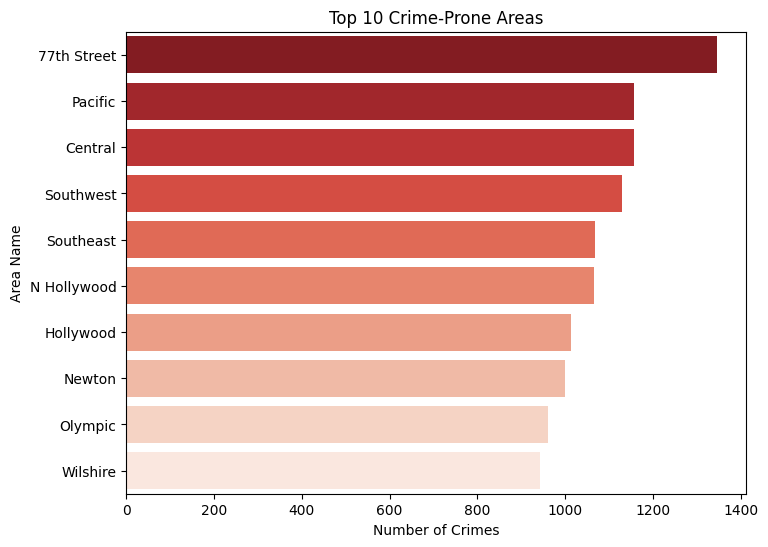

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Area_Name and count crimes
crime_by_area = df["Area_Name"].value_counts().head(10)

# Plot crime distribution by area
plt.figure(figsize=(8, 6))
sns.barplot(x=crime_by_area.values, y=crime_by_area.index, palette="Reds_r")

plt.xlabel("Number of Crimes")
plt.ylabel("Area Name")
plt.title("Top 10 Crime-Prone Areas")
plt.show()


*Crime distribution by premise type*

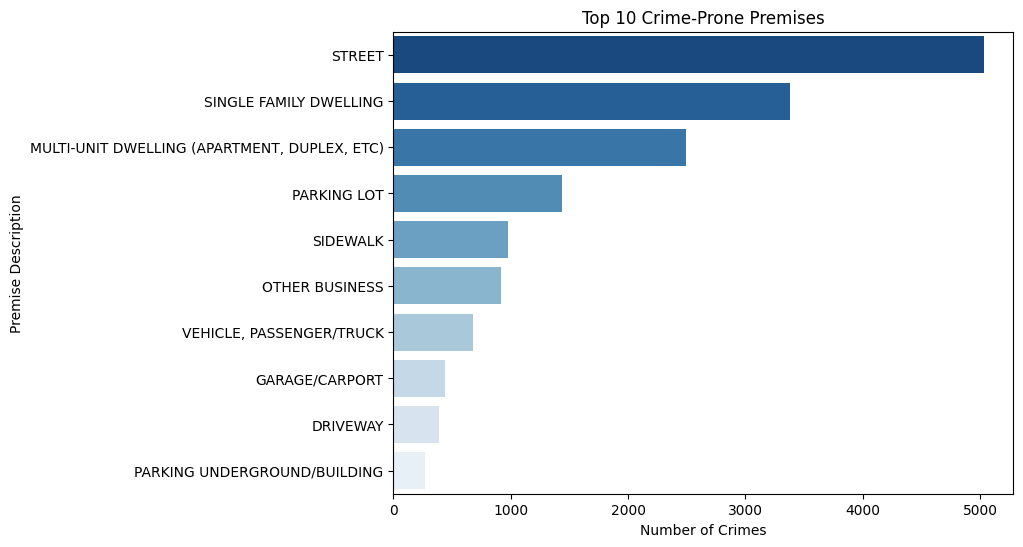

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Premise_Description and count crimes
crime_by_premise = df["Premise_Description"].value_counts().head(10)

# Plot crime distribution by premise type
plt.figure(figsize=(8, 6))
sns.barplot(x=crime_by_premise.values, y=crime_by_premise.index, palette="Blues_r")

plt.xlabel("Number of Crimes")
plt.ylabel("Premise Description")
plt.title("Top 10 Crime-Prone Premises")
plt.show()


*age distribution*

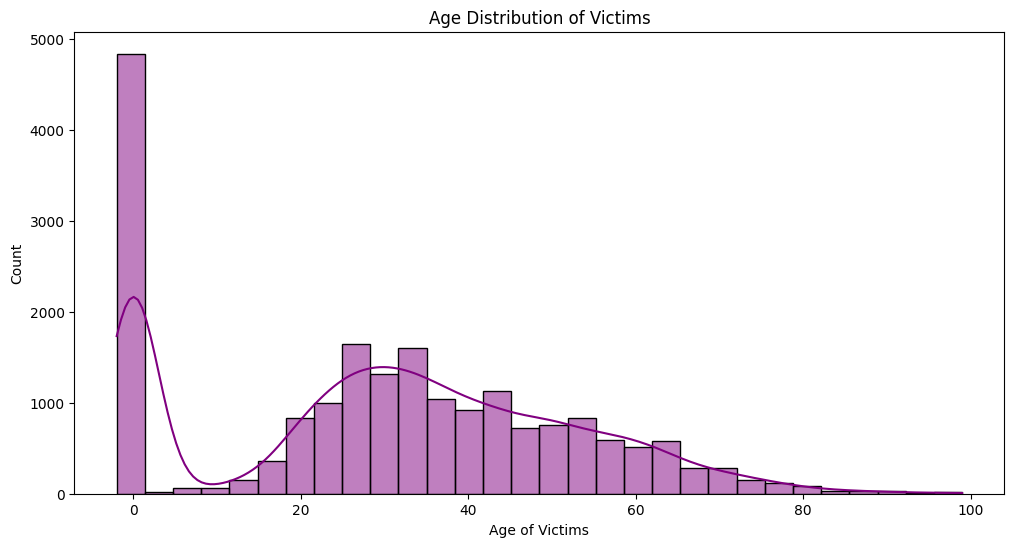

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot age distribution
plt.figure(figsize=(12, 6))
sns.histplot(df["Victim_Age"].dropna(), bins=30, kde=True, color="purple")

plt.xlabel("Age of Victims")
plt.ylabel("Count")
plt.title("Age Distribution of Victims")
plt.show()


*Distribution by Victim_Sex and Victim Descent*

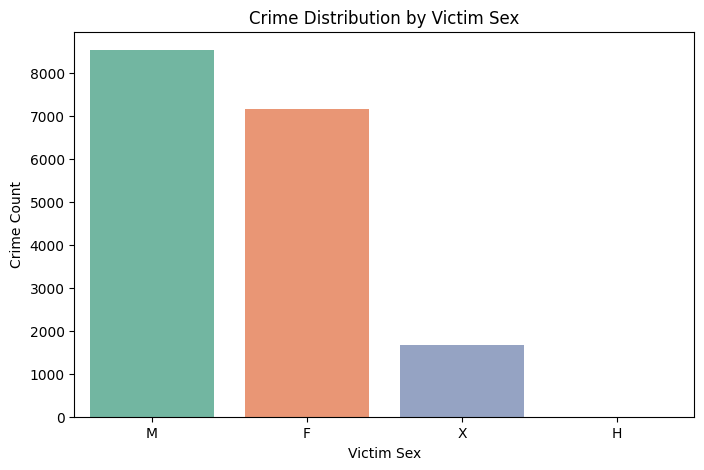

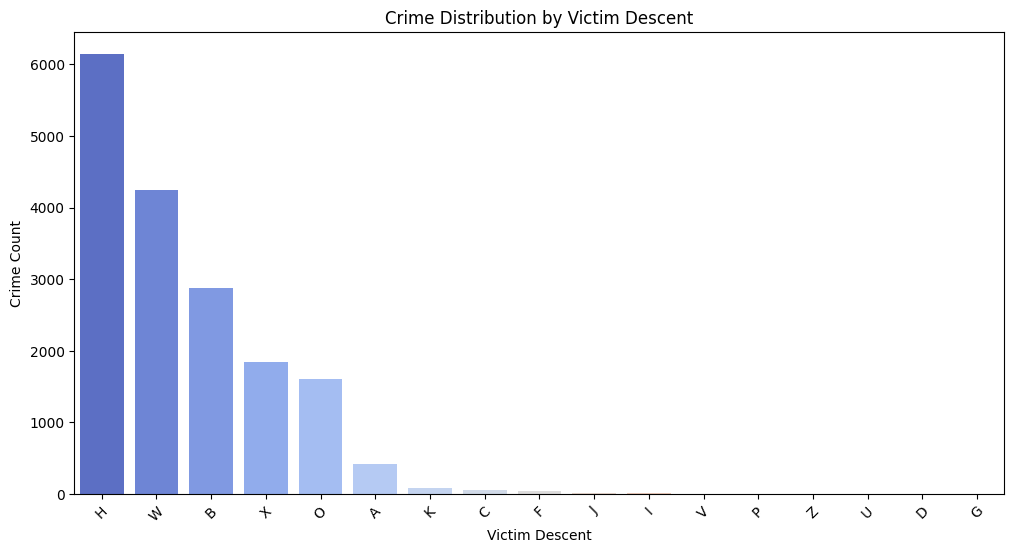

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Crime distribution by Victim_Sex
plt.figure(figsize=(8, 5))
sns.countplot(x=df["Victim_Sex"], palette="Set2", order=df["Victim_Sex"].value_counts().index)
plt.xlabel("Victim Sex")
plt.ylabel("Crime Count")
plt.title("Crime Distribution by Victim Sex")
plt.show()

# Crime distribution by Victim_Descent
plt.figure(figsize=(12, 6))
sns.countplot(x=df["Victim_Descent"], palette="coolwarm", order=df["Victim_Descent"].value_counts().index)
plt.xlabel("Victim Descent")
plt.ylabel("Crime Count")
plt.title("Crime Distribution by Victim Descent")
plt.xticks(rotation=45)
plt.show()


*top 10 most commonly used weapons*

Weapon_Description
STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)    3990
UNKNOWN WEAPON/OTHER WEAPON                        789
VERBAL THREAT                                      546
HAND GUN                                           388
KNIFE WITH BLADE 6INCHES OR LESS                   160
SEMI-AUTOMATIC PISTOL                              154
UNKNOWN FIREARM                                    131
OTHER KNIFE                                        125
VEHICLE                                             84
MACE/PEPPER SPRAY                                   80
Name: count, dtype: int64


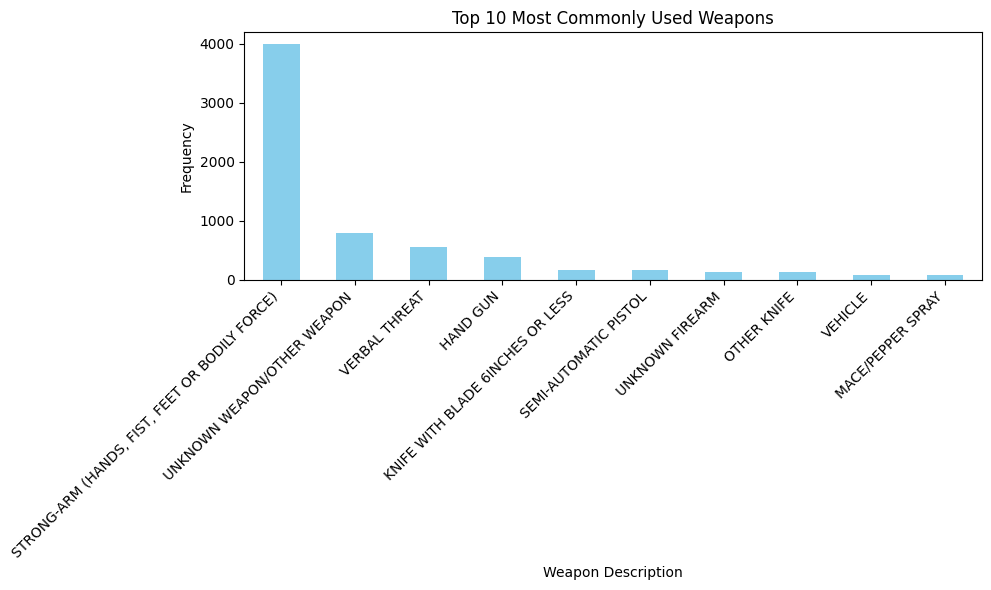

In [27]:
import pandas as pd
import matplotlib.pyplot as plt


# Count the occurrences of each Weapon_Description
weapon_counts = df['Weapon_Description'].value_counts()

# Display the top 10 most commonly used weapons
print(weapon_counts.head(10))

# Plot the most commonly used weapons (top 10)
plt.figure(figsize=(10, 6))
weapon_counts.head(10).plot(kind='bar', color='skyblue')
plt.title('Top 10 Most Commonly Used Weapons')
plt.xlabel('Weapon Description')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


*top 10 most frequent crime categories*

Crime_Category
Property Crimes                  11666
Violent Crimes                    4767
Crimes against Public Order       1808
Fraud and White-Collar Crimes     1355
Crimes against Persons             225
Other Crimes                       179
Name: count, dtype: int64


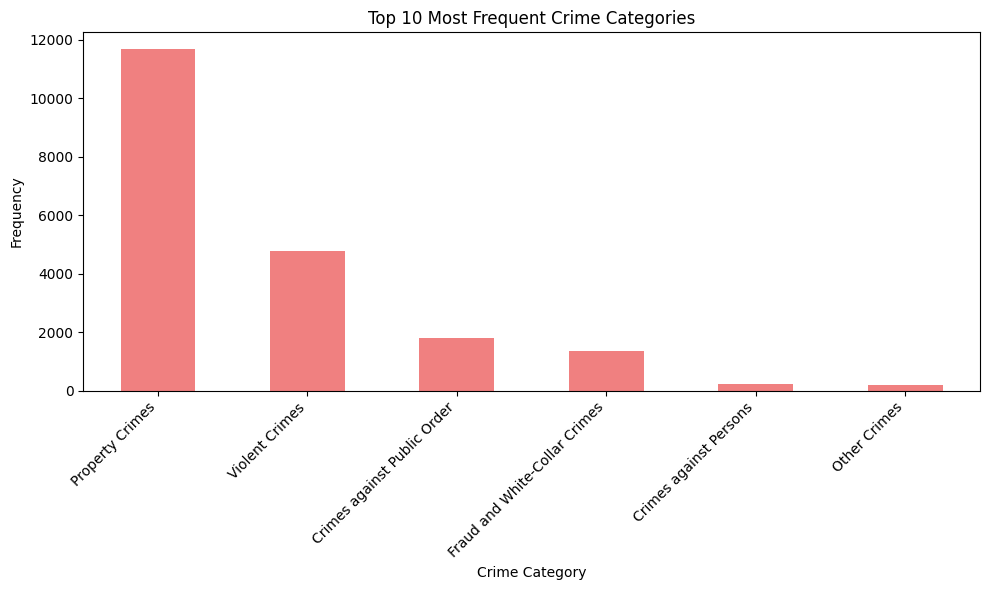

In [28]:
import pandas as pd
import matplotlib.pyplot as plt


# Count the occurrences of each Crime_Category
crime_category_counts = df['Crime_Category'].value_counts()

# Display the top 10 most frequent crime categories
print(crime_category_counts.head(10))

# Plot the most frequent crime categories (top 10)
plt.figure(figsize=(10, 6))
crime_category_counts.head(10).plot(kind='bar', color='lightcoral')
plt.title('Top 10 Most Frequent Crime Categories')
plt.xlabel('Crime Category')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


*crime distribution by area*

<Figure size 1000x600 with 0 Axes>

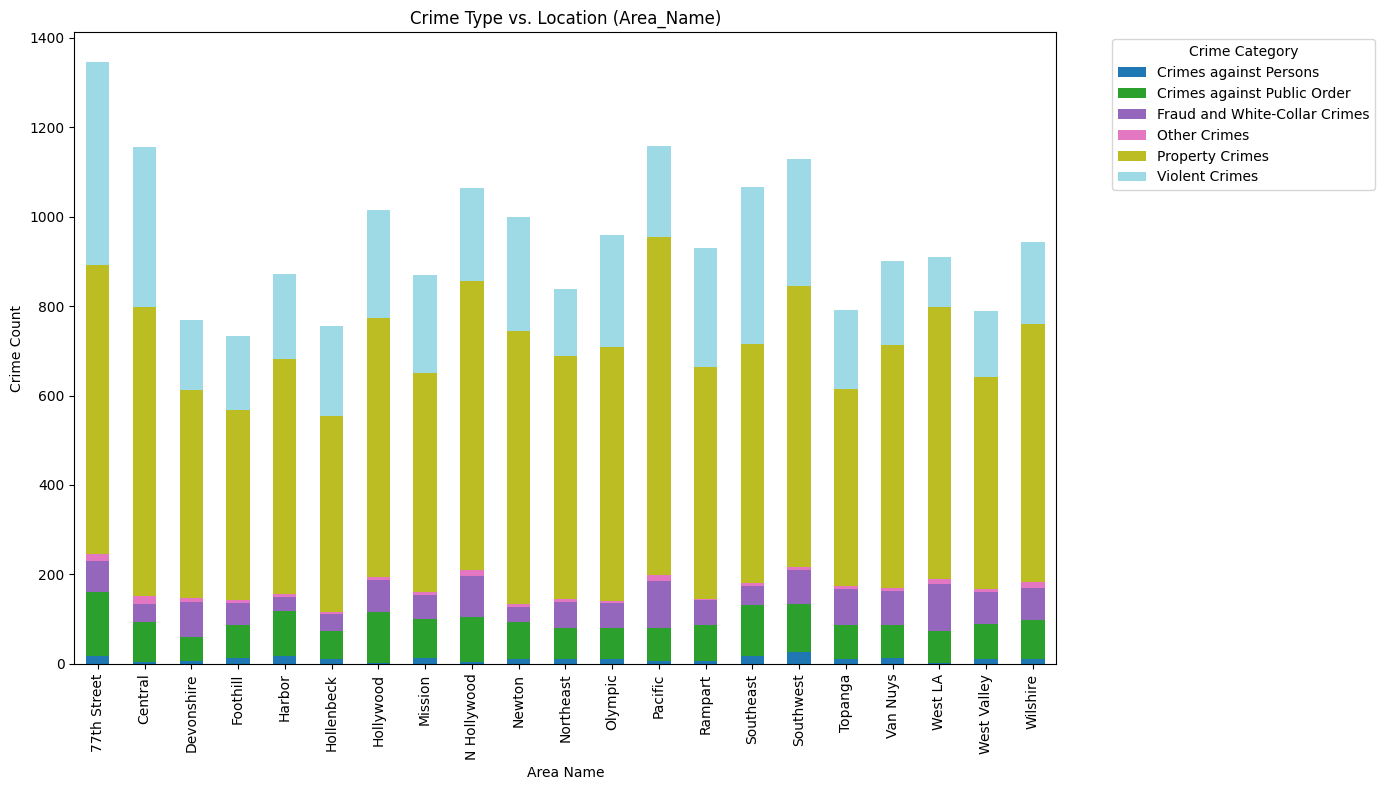

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
# Group by 'Area_Name' and 'Crime_Category' and count the occurrences
crime_by_area = df.groupby(['Area_Name', 'Crime_Category']).size().unstack(fill_value=0)

# Plot the crime distribution by area
plt.figure(figsize=(10,6 ))
crime_by_area.plot(kind='bar', stacked=True, figsize=(14, 8), cmap='tab20')
plt.title('Crime Type vs. Location (Area_Name)')
plt.xlabel('Area Name')
plt.ylabel('Crime Count')
plt.xticks(rotation=90)
plt.legend(title='Crime Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


*distribution of 'Crime_Category' and  'Status_Description'*

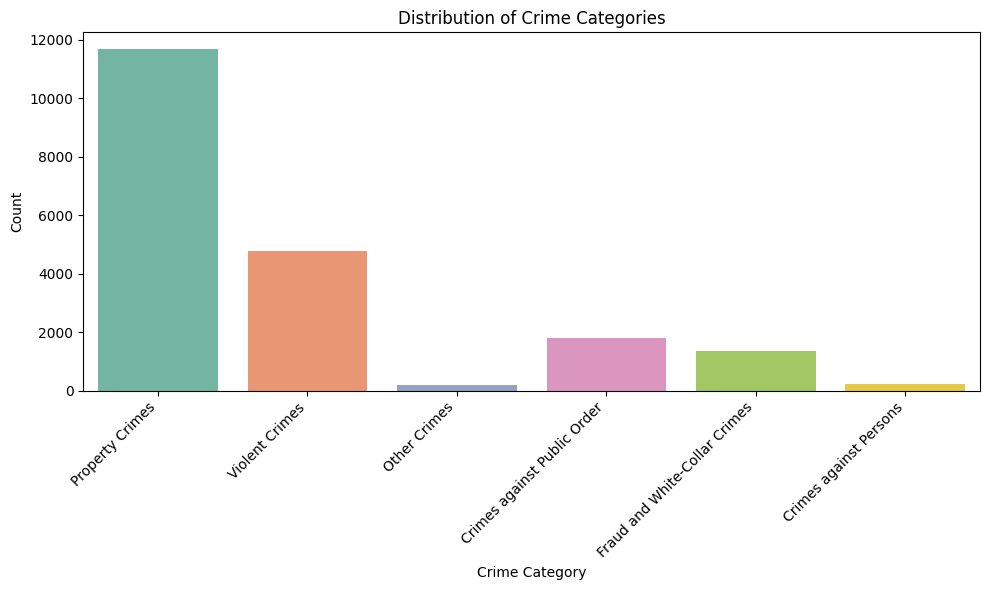

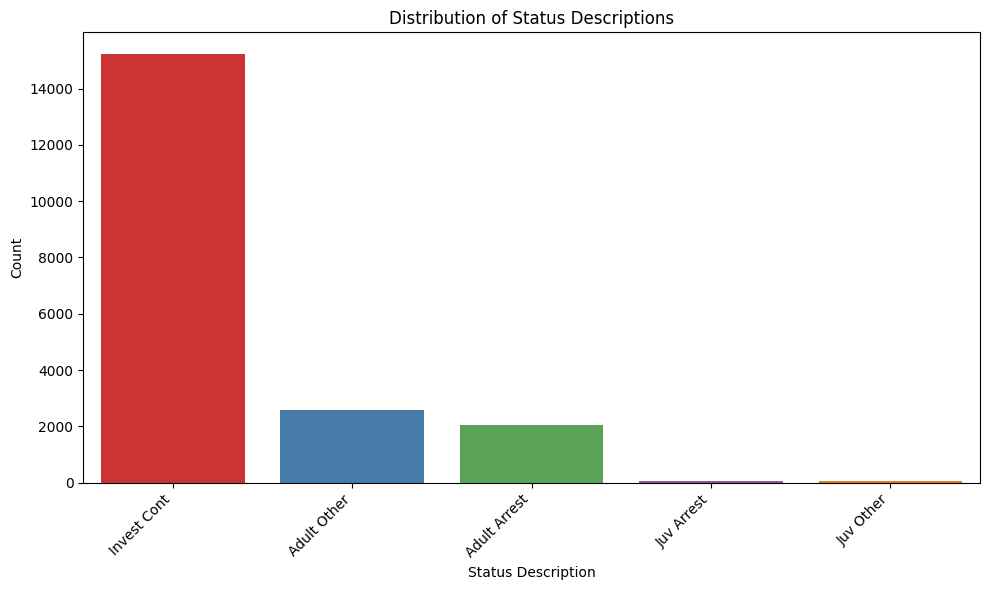

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the distribution of 'Crime_Category'
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Crime_Category', palette='Set2')
plt.title('Distribution of Crime Categories')
plt.xlabel('Crime Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plotting the distribution of 'Status_Description'
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Status_Description', palette='Set1')
plt.title('Distribution of Status Descriptions')
plt.xlabel('Status Description')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



*Dropping Unneccesary Columns*

In [31]:
# Drop the specified columns
columns_to_drop = ['Modus_Operandi','Weapon_Description','Part 1-2','Victim_Descent','Time_Occurred','Status_Description','Cross_Street','Premise_Description','Date_Occurred']  # Replace with the exact column names or indices
df = df.drop(columns=columns_to_drop, errors='ignore')

*label Encoding*

In [32]:
from sklearn.preprocessing import LabelEncoder

# List of categorical columns to encode
categorical_columns = ['Location','Area_Name','Victim_Sex','Status','Date_Reported']

# Initialize the label encoder
label_encoder = LabelEncoder()

# Apply label encoding to each of the categorical columns
for col in categorical_columns:
    df[col] = label_encoder.fit_transform(df[col])

# Display the first few rows of the updated dataset
df.head()


,Location,Latitude,Longitude,Date_Reported,Area_ID,Area_Name,Reporting_District_no,Victim_Age,Victim_Sex,Premise_Code,Weapon_Used_Code,Status,Crime_Category
0,7238,34.1522,-118.3910,192,15.0,8,1563.0,75.0,2,101.0,NaN,2,Property Crimes
1,7300,34.0028,-118.2391,160,13.0,9,1367.0,41.0,2,216.0,400.0,2,Property Crimes
2,8525,34.0111,-118.2653,568,13.0,9,1343.0,67.0,2,501.0,NaN,2,Property Crimes
3,2879,34.2953,-118.4590,712,19.0,7,1924.0,61.0,2,101.0,NaN,2,Property Crimes
4,9584,33.9787,-118.2918,155,12.0,0,1245.0,0.0,3,401.0,400.0,2,Property Crimes


*TargetVariable*

In [33]:
df['Crime_Category'].value_counts()

Crime_Category
Property Crimes                  11666
Violent Crimes                    4767
Crimes against Public Order       1808
Fraud and White-Collar Crimes     1355
Crimes against Persons             225
Other Crimes                       179
Name: count, dtype: int64

In [34]:
# Initialize LabelEncoder
label_encoder = LabelEncoder()
# Encoding 'Crime_Category' column 
df['Crime_Category'] = label_encoder.fit_transform(df['Crime_Category'])
df['Crime_Category'].value_counts()

Crime_Category
4    11666
5     4767
1     1808
2     1355
0      225
3      179
Name: count, dtype: int64

*Data Correlation*

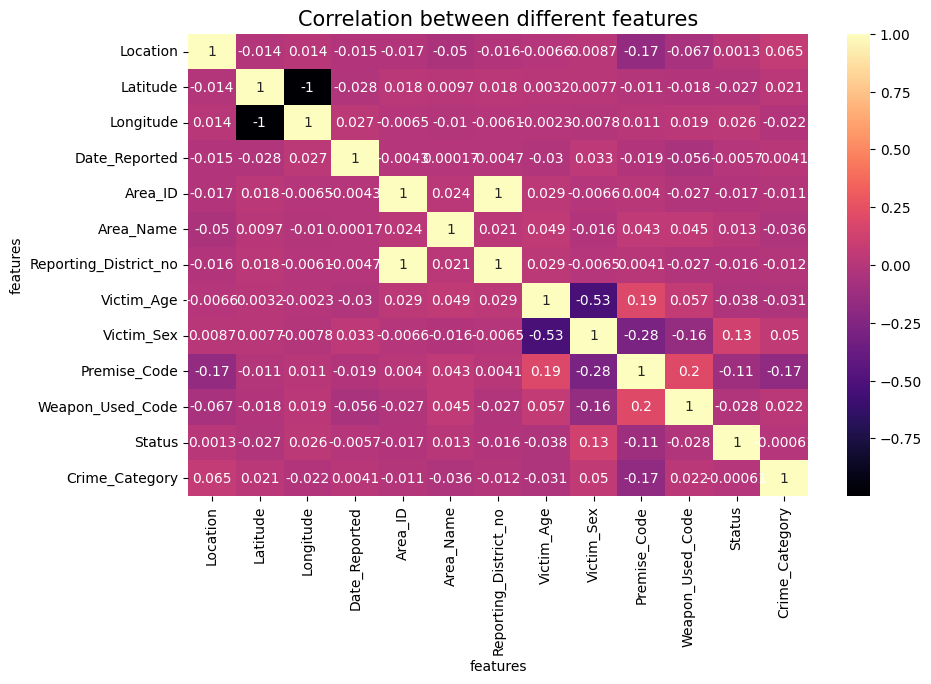

In [35]:

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.heatmap(df.corr(), annot=True,cmap='magma')
ax.set(xlabel='features')
ax.set(ylabel='features')

plt.title('Correlation between different features', fontsize = 15, c='black')
plt.show()

*Filling NAN Values*

*Filling 

In [36]:
# Impute missing values in the 'Weapon_Used_Code' column with the median
df['Weapon_Used_Code'] = df['Weapon_Used_Code'].fillna(df['Weapon_Used_Code'].median())

# Check the result
print(df['Weapon_Used_Code'])


0        400.0
1        400.0
2        400.0
3        400.0
4        400.0
         ...  
19995    400.0
19996    400.0
19997    400.0
19998    400.0
19999    400.0
Name: Weapon_Used_Code, Length: 20000, dtype: float64


In [37]:
# Drop rows with NaN values in 'Weapon_Used_Code' column
df = df.dropna(subset=['Weapon_Used_Code'])

# Check the result
print(df['Weapon_Used_Code'])


0        400.0
1        400.0
2        400.0
3        400.0
4        400.0
         ...  
19995    400.0
19996    400.0
19997    400.0
19998    400.0
19999    400.0
Name: Weapon_Used_Code, Length: 20000, dtype: float64


*Saving Cleaned File*

In [38]:
df.to_csv('crime_cleaned_data.csv',index=False)

crime = pd.read_csv('crime_cleaned_data.csv')
crime

,Location,Latitude,Longitude,Date_Reported,Area_ID,Area_Name,Reporting_District_no,Victim_Age,Victim_Sex,Premise_Code,Weapon_Used_Code,Status,Crime_Category
0,7238,34.1522,-118.3910,192,15.0,8,1563.0,75.0,2,101.0,400.0,2,4
1,7300,34.0028,-118.2391,160,13.0,9,1367.0,41.0,2,216.0,400.0,2,4
2,8525,34.0111,-118.2653,568,13.0,9,1343.0,67.0,2,501.0,400.0,2,4
3,2879,34.2953,-118.4590,712,19.0,7,1924.0,61.0,2,101.0,400.0,2,4
4,9584,33.9787,-118.2918,155,12.0,0,1245.0,0.0,3,401.0,400.0,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,7868,34.0334,-118.3523,379,3.0,15,303.0,51.0,2,501.0,400.0,2,5
19996,3555,34.2212,-118.5011,800,10.0,19,1008.0,0.0,2,301.0,400.0,2,4
19997,441,34.0571,-118.3815,632,8.0,18,849.0,42.0,2,102.0,400.0,2,4
19998,5975,33.7451,-118.2835,418,5.0,4,558.0,76.0,0,501.0,400.0,2,1


# Machine learning models

## Models we will use:

* **Decision Tree** 
* **Adaptive Region Partitioning (ARP)**
* **Logistic Regression**
* **Ada Boost**
* **LGBM**
* **ANN**

*Splitting of Data*

In [39]:
from sklearn.model_selection import train_test_split

# Assume df is your DataFrame
# Define feature set and target label
X = df.drop(columns=['Crime_Category'])
y = df['Crime_Category']


# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,            # Features
    y,            # Target labels
    test_size=0.3, # Proportion of the dataset to include in the test split
    random_state=11 # Seed for the random number generator
)

# Optionally, print the shapes of the resulting splits
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (14000, 12)
y_train shape:  (14000,)
X_test shape:  (6000, 12)
y_test shape:  (6000,)


*Decision Tree*

In [40]:
from sklearn.tree import DecisionTreeClassifier 
# Initializing
DT = DecisionTreeClassifier()
DT.fit(X_train, y_train)
from sklearn.model_selection import cross_val_score

# y_predict = DT.predict(X_test)
print('*'*20)

# prediction
train_pred=DT.predict(X_train)
test_pred= DT.predict(X_test)
print('*'*20)
# accuracy
print('Train accuracy:' , accuracy_score(y_train,train_pred))
print('Test accuracy:' , accuracy_score(y_test,test_pred))

print('*'*20)
 # cross validation   
score= cross_val_score(DT,X,y,cv=5)
print(score)
print(score.mean())

print('*'*20)
#  prediction Summary by species
print(classification_report(y_test, test_pred))

print('*'*20)
# Accuracy score
DT_SC = accuracy_score(y_train,train_pred)
print(f"{round(DT_SC*100,2)}% Accurate")

print('*'*20)

********************
********************
Train accuracy: 0.9999285714285714
Test accuracy: 0.6195
********************
[0.62575 0.6195  0.63275 0.62625 0.62725]
0.6263
********************
              precision    recall  f1-score   support

           0       0.35      0.40      0.37        63
           1       0.37      0.38      0.37       539
           2       0.30      0.31      0.31       401
           3       0.05      0.08      0.06        52
           4       0.76      0.75      0.76      3486
           5       0.51      0.50      0.50      1459

    accuracy                           0.62      6000
   macro avg       0.39      0.40      0.40      6000
weighted avg       0.62      0.62      0.62      6000

********************
99.99% Accurate
********************


*Adaptive Region Partitioning (ARP)*

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initiallizing 
rfc=RandomForestClassifier(random_state=42)
rfc.fit(X_train,y_train)
print('*'*20)

# prediction
train_prediction= rfc.predict(X_train)
test_prediction= rfc.predict(X_test)
print('*'*20)

# evaluation
from sklearn.metrics import accuracy_score
print('test accuracy:',accuracy_score(y_test,test_prediction))
print('train accuracy:',accuracy_score(y_train,train_prediction))
print('*'*20)

# # cross validation score
from sklearn.model_selection import cross_val_score
score=cross_val_score(rfc,X,y,cv=5)
print(score.mean())
print('*'*20)

#  prediction 
print(classification_report(y_test, test_prediction))
print('*'*20)

# Accuracy score
RF_SC = accuracy_score(test_prediction,y_test)
print(f"{round(RF_SC*100,2)}% Accurate")

********************
********************
test accuracy: 0.7108333333333333
train accuracy: 0.9999285714285714
********************


*Logistic Regression*

In [50]:
from sklearn.linear_model import LogisticRegression

# Initializing 
LR = LogisticRegression()
LR.fit(X_train, y_train)


# prediction
train_prediction= LR.predict(X_train)
test_prediction= LR.predict(X_test)
print('*'*20)

# evaluation
from sklearn.metrics import accuracy_score
print('test accuracy:',accuracy_score(y_test,test_prediction))
print('train accuracy:',accuracy_score(y_train,train_prediction))
print('*'*20)

# cross validation score
from sklearn.model_selection import cross_val_score
score=cross_val_score(LR,X,y,cv=5)
print(score.mean())
print('*'*20)

print(classification_report(y_test,test_pred))

print('*'*20)


lr_HSC = accuracy_score(y_test,test_prediction)
print(f"{round(lr_HSC*100,2)}% Accurate")

********************
test accuracy: 0.5763333333333334
train accuracy: 0.584
********************
0.5849
********************
              precision    recall  f1-score   support

           0       0.36      0.46      0.40        63
           1       0.36      0.38      0.37       539
           2       0.29      0.30      0.30       401
           3       0.07      0.08      0.07        52
           4       0.76      0.75      0.75      3486
           5       0.51      0.50      0.50      1459

    accuracy                           0.62      6000
   macro avg       0.39      0.41      0.40      6000
weighted avg       0.62      0.62      0.62      6000

********************
57.63% Accurate


*AdaBoost*

In [51]:
from sklearn.ensemble import AdaBoostClassifier

# Initializing AdaBoost Classifier
adb_model = AdaBoostClassifier(
    n_estimators=50,        # Number of weak learners (default is 50)
    random_state=11         # Seed for reproducibility
)

# Fitting the model
adb_model.fit(X_train, y_train)

# Predictions
train_prediction = adb_model.predict(X_train)
test_prediction = adb_model.predict(X_test)
print('*' * 20)

# Evaluation
print('Test accuracy:', accuracy_score(y_test, test_prediction))
print('Train accuracy:', accuracy_score(y_train, train_prediction))
print('*' * 20)


# Classification report
print('Classification report:\n', classification_report(y_test, test_prediction))
print('*' * 20)

# AdaBoost model accuracy
adb_HSC = accuracy_score(y_test, test_prediction)
print(f"{round(adb_HSC * 100, 2)}% Accurate")

********************
Test accuracy: 0.5588333333333333
Train accuracy: 0.5597142857142857
********************
Classification report:
               precision    recall  f1-score   support

           0       0.28      0.48      0.36        63
           1       0.70      0.17      0.27       539
           2       0.19      0.53      0.28       401
           3       0.03      0.10      0.04        52
           4       0.77      0.64      0.70      3486
           5       0.51      0.54      0.52      1459

    accuracy                           0.56      6000
   macro avg       0.41      0.41      0.36      6000
weighted avg       0.65      0.56      0.58      6000

********************
55.88% Accurate


*LGBM*

In [52]:
import lightgbm as lgb
from sklearn.model_selection import cross_val_score

# Initializing LGBM Classifier
lgbm_model = lgb.LGBMClassifier(
    n_estimators=100,        # Number of boosting rounds
    random_state=11          # Seed for reproducibility
)

# Fitting the model
lgbm_model.fit(X_train, y_train)

# Predictions
train_prediction = lgbm_model.predict(X_train)
test_prediction = lgbm_model.predict(X_test)
print('*' * 20)

# Evaluation
print('Test accuracy:', accuracy_score(y_test, test_prediction))
print('Train accuracy:', accuracy_score(y_train, train_prediction))
print('*' * 20)

# Cross-validation score
score = cross_val_score(lgbm_model, X, y, cv=5)
print('Cross-validation score mean:', score.mean())
print('*' * 20)

# Classification report
print('Classification report:\n', classification_report(y_test, test_prediction))
print('*' * 20)

# LGBM model accuracy
lgbm_HSC = accuracy_score(y_test, test_prediction)
print(f"{round(lgbm_HSC * 100, 2)}% Accurate")


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011082 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1593
[LightGBM] [Info] Number of data points in the train set: 14000, number of used features: 12
[LightGBM] [Info] Start training from score -4.459216
[LightGBM] [Info] Start training from score -2.400828
[LightGBM] [Info] Start training from score -2.686149
[LightGBM] [Info] Start training from score -4.702626
[LightGBM] [Info] Start training from score -0.537365
[LightGBM] [Info] Start training from score -1.442714
********************
Test accuracy: 0.7158333333333333
Train accuracy: 0.8587857142857143
********************
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000548 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_co

*ANN*

In [53]:
from keras.models import Sequential
from keras.layers import Dense

# Define the model
ann = Sequential()
ann.add(Dense(units=64, input_dim=X_train.shape[1], kernel_initializer='uniform', activation='relu'))  # input_dim should be the number of features
ann.add(Dense(units=32, kernel_initializer='uniform', activation='relu'))
ann.add(Dense(units=1, kernel_initializer='uniform', activation='sigmoid'))

# Compile the model
ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Fit the model
ann.fit(X_train, y_train, epochs=15, batch_size=32)

from sklearn.metrics import accuracy_score,confusion_matrix

print('test accuracy:', accuracy_score(y_test,test_prediction))
print('train accuracy:', accuracy_score(y_train,train_prediction))
print(confusion_matrix(y_test,test_prediction))


ann_hc = accuracy_score(y_test,test_prediction)
print(f"{round(ann_hc*100,2)}% Accurate")

Epoch 1/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.0858 - loss: -499905.0000
Epoch 2/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.0874 - loss: -21561500.0000
Epoch 3/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.0943 - loss: -116860536.0000
Epoch 4/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.0895 - loss: -327313504.0000
Epoch 5/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0900 - loss: -675711296.0000
Epoch 6/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0929 - loss: -1173825152.0000
Epoch 7/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0907 - loss: -1854037504.0000
Epoch 8/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0910 - loss: -2685780480.0000
Epoch 9/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0959 - loss: -3684405504.0000
Epoch 10/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0908 - loss: -4986575360.0000
Epoch 11/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/

*Comparision*

In [64]:
score = [DT_SC,RF_SC,lgbm_HSC,adb_HSC,lr_HSC,ann_hc]
Models = pd.DataFrame({
    'n_neighbors': ["Decision Tree","Adaptive Region Partitioning (ARP)","Lightgbm","AdaBoostClassifier","Logistic Regression","ANN"],
    'Score': score})
Models.sort_values(by='Score', ascending=False)

,n_neighbors,Score
0,Decision Tree,0.999929
2,Lightgbm,0.715833
5,ANN,0.715833
1,Random Forest,0.710833
4,Logistic Regression,0.576333
3,AdaBoostClassifier,0.558833


*Saving Model*

In [65]:
import pickle 

In [66]:
# save the model
model = DT  # Your machine learning model object
file_path = 'DT-cyber.pkl'  # Path to the file where you want to save the model

with open(file_path, 'wb') as file:
    pickle.dump(model, file)

In [67]:
import pickle
# load the model

file_path = 'DT-cyber.pkl'  # Path to the saved model file

with open(file_path, 'rb') as file:
    loaded_model = pickle.load(file)

*User's Prediction*

In [69]:
loaded_model.predict([[7238,34.1522,-118.391,192,15.0,8,1563.0,75.0,2,101.0,400.0,2]])

array([4])

In [70]:
loaded_model.predict([[5828,34.1127,-118.1942,25,11.0,10,1118.0,50.0,2,502.0,400.0,1]])

array([5])

In [71]:
loaded_model.predict([[11202,   ,-118.3277,147,6.0,6,666.0,50.0,2,102.0,207.0,2]])

array([1])